# Task 1 · Innovation — Named entities in Peruvian news

**Guiding question:** Which people, organizations and places dominate each news category?

Whereas Parts 1 and 2 classified headlines into thematic categories, this complementary analysis examines *who* and *what* the news is about. To this end, a named entity recognition (NER) model is applied to the 383 news items, and the most frequent entities are identified within each category. Accordingly, the analysis offers a substantive reading of the corpus that complements the classifier: it reveals which actors structure the agenda of each section and, in doing so, helps explain the vocabulary that the model relies upon.

In [1]:
import pandas as pd
import plotly.express as px
import plotly.io as pio
from transformers import pipeline

This cell loads the libraries required for the analysis. Specifically, `transformers` provides access to the pretrained NER model, whereas `pandas` organizes the extracted entities and `plotly` renders the interactive charts.

In [2]:
# =============================================
#  CONFIGURATION
# =============================================

# Interactive figure in VS Code plus a static PNG copy that GitHub can display.
pio.renderers.default = "plotly_mimetype+png"

modelo_ner = "mrm8488/bert-spanish-cased-finetuned-ner"

# Only entities detected with high confidence are kept, to reduce false positives.
umbral_confianza = 0.80

# People, organizations and locations; the residual MISC type is excluded.
tipos_relevantes = ["PER", "ORG", "LOC"]

noticias = pd.read_csv("datos/noticias.csv")
print(noticias.shape)

(383, 7)


The configuration cell centralizes the parameters of the analysis. The model `mrm8488/bert-spanish-cased-finetuned-ner`, suggested by the assignment, is a Spanish BERT fine-tuned to recognize people (`PER`), organizations (`ORG`), locations (`LOC`) and miscellaneous entities (`MISC`). Since the latter type groups heterogeneous items, only the first three are retained. Furthermore, a confidence threshold of 0.80 is applied in order to discard uncertain detections, thereby favoring precision over recall.

## 1. Entity extraction

The NER model is applied to the headline and the summary of each news item. Combining both fields increases the number of entities detected, given that headlines often mention actors only by their surname, whereas summaries tend to identify them in full.

In [3]:
# "simple" aggregation merges the pieces of multi-word entities, e.g. "Keiko" + "Fujimori".
reconocedor = pipeline("ner", model=modelo_ner, aggregation_strategy="simple")

config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

c:\Users\Ana Karen\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Ana Karen\.cache\huggingface\hub\models--mrm8488--bert-spanish-cased-finetuned-ner. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\Ana Karen\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarnin

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  439MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  439MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

The NER pipeline is loaded with the `simple` aggregation strategy, which merges the individual tokens of a multi-word entity into a single item. Without this option, a name such as *Keiko Fujimori* would be split into separate fragments and counted incorrectly.

In [4]:
lista_entidades = []

for posicion, fila in noticias.iterrows():
    texto = f"{fila['titular']}. {fila['bajada']}"

    for entidad in reconocedor(texto):
        # The entity is read from the original text, which avoids broken sub-word fragments.
        nombre = texto[entidad["start"]:entidad["end"]].strip(" .,;:\"“”'‘’()")

        if entidad["score"] >= umbral_confianza and len(nombre) >= 3:
            lista_entidades.append({
                "etiqueta": fila["etiqueta"],
                "tipo": entidad["entity_group"],
                "entidad": nombre,
                "confianza": round(float(entidad["score"]), 3),
            })

    # Progress message every 100 news items.
    if posicion % 100 == 0:
        print(posicion, "news items processed")

0 news items processed
100 news items processed
200 news items processed
300 news items processed


The loop processes each news item and stores every entity that satisfies two conditions: a confidence of at least 0.80 and a minimum length of three characters, which filters out isolated initials and residual fragments. Importantly, each entity is recovered directly from the original text through its character positions and stripped of surrounding punctuation, which yields clean names regardless of how the model segments words internally.

In [5]:
entidades = pd.DataFrame(lista_entidades)
entidades = entidades[entidades["tipo"].isin(tipos_relevantes)]

frecuencias = (
    entidades.groupby(["etiqueta", "tipo", "entidad"])
    .size()
    .reset_index(name="frecuencia")
    .sort_values(["etiqueta", "frecuencia"], ascending=[True, False])
)
frecuencias.to_csv("datos/entidades.csv", index=False)

print("Entity mentions :", entidades.shape[0])
print("Unique entities :", frecuencias.shape[0])
entidades["tipo"].value_counts()

Entity mentions : 1413
Unique entities : 717


tipo
ORG    774
PER    390
LOC    249
Name: count, dtype: int64

The detected entities are gathered into a DataFrame, restricted to the three relevant types, and subsequently aggregated by category, type and name, so as to obtain the frequency of each entity within each category. The resulting table is exported to `datos/entidades.csv`, which allows the dashboard to display the entities without running the NER model again.

In total, 1,413 entity mentions were retained, corresponding to 717 unique entities. Organizations constitute the most frequent type (774 mentions), followed by people (390) and locations (249). This distribution is consistent with the nature of news coverage, which tends to revolve around institutions such as Congress, ministries, companies and sports clubs.

## 2. Most frequent entities per category

The eight most frequent entities of each category are displayed below, distinguishing between people, organizations and locations.

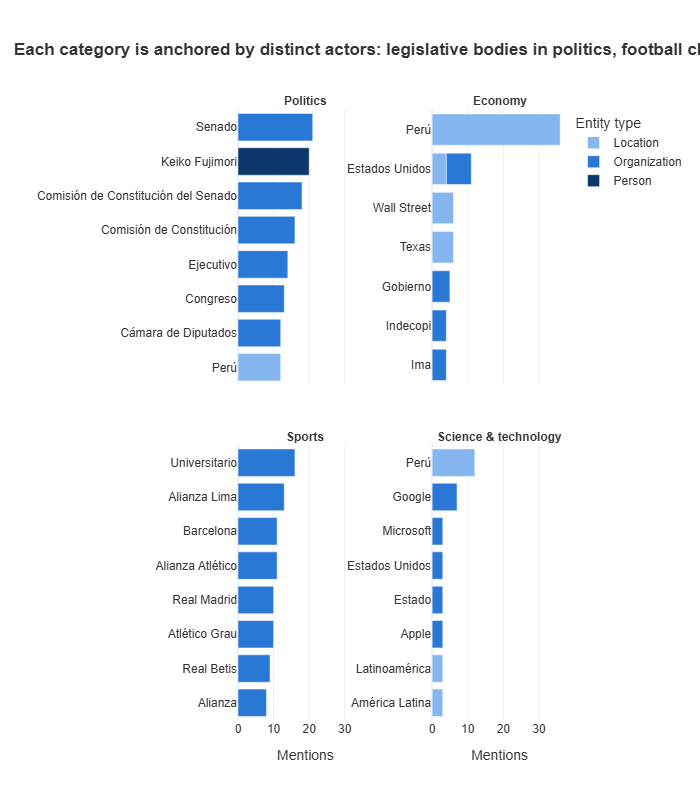

In [8]:
nombres_categorias = {
    "politica": "Politics",
    "economia": "Economy",
    "deportes": "Sports",
    "ciencia_tecnologia": "Science & technology",
}
nombres_tipos = {"PER": "Person", "ORG": "Organization", "LOC": "Location"}

# Same blue palette used in the previous notebooks.
colores_tipos = {"Person": "#0d366b", "Organization": "#2a78d6", "Location": "#86b6ef"}

top_entidades = frecuencias.groupby("etiqueta").head(8).copy()
top_entidades["categoria"] = top_entidades["etiqueta"].map(nombres_categorias)
top_entidades["tipo_nombre"] = top_entidades["tipo"].map(nombres_tipos)

fig = px.bar(
    top_entidades, x="frecuencia", y="entidad", color="tipo_nombre", orientation="h",
    facet_col="categoria", facet_col_wrap=2, facet_col_spacing=0.18, facet_row_spacing=0.1,
    category_orders={"categoria": list(nombres_categorias.values())},
    color_discrete_map=colores_tipos,
    labels={"frecuencia": "Mentions", "entidad": "", "tipo_nombre": "Entity type"},
    title="<b>Each category is anchored by distinct actors: legislative bodies in politics, football clubs in sports</b>",
    height=800,
)

# Each panel keeps its own entities, ordered from the most frequent (top) to the least frequent.
fig.update_yaxes(matches=None, showticklabels=True, categoryorder="total ascending")
fig.for_each_annotation(lambda anotacion: anotacion.update(text=f"<b>{anotacion.text.split('=')[-1]}</b>"))
fig.update_layout(
    template="plotly_white",
    font=dict(family="Arial", size=12, color="#333333"),
    title=dict(font=dict(size=17), x=0.02, xanchor="left"),
    margin=dict(t=110),
)
fig.show()

The chart reveals that each category is anchored by a distinct set of actors, which supports the internal coherence of the four categories. Politics is dominated by legislative institutions, namely the Senate (21 mentions), its Constitutional Committee and the Executive, together with President Keiko Fujimori (20), the only individual among the most frequent entities across all categories; this concentration mirrors the parliamentary debate on legislative powers that marked the period under study. Sports, in turn, revolves almost exclusively around football clubs, both domestic (Universitario, Alianza Lima, Alianza Atlético, Atlético Grau) and Spanish (Barcelona, Real Madrid, Real Betis). By contrast, economy and science and technology are structured mainly by locations and corporations: Peru is the single most cited entity in economy (36), followed by international references such as the United States and Wall Street, whereas technology news is characterized by global firms such as Google, Apple and Microsoft.

These patterns also help explain the classifier's behavior observed in Part 2. Sports entities are highly distinctive and rarely appear elsewhere, which is consistent with the flawless classification of that category. Conversely, generic entities such as *Peru*, *the State* or *the Government* appear across several categories, and political institutions frequently surface in economic news, which offers a substantive explanation for the confusion between politics and economy.

In [7]:
# Compact summary: the five most frequent entities of each category.
for etiqueta, nombre in nombres_categorias.items():
    principales = frecuencias[frecuencias["etiqueta"] == etiqueta].head(5)
    lista = ", ".join(f"{fila.entidad} ({fila.frecuencia})" for fila in principales.itertuples())
    print(f"{nombre}: {lista}")

Politics: Senado (21), Keiko Fujimori (20), Comisión de Constitución del Senado (18), Comisión de Constitución (16), Ejecutivo (14)
Economy: Perú (36), Estados Unidos (7), Texas (6), Wall Street (6), Gobierno (5)
Sports: Universitario (16), Alianza Lima (13), Alianza Atlético (11), Barcelona (11), Atlético Grau (10)
Science & technology: Perú (12), Google (7), América Latina (3), Latinoamérica (3), Apple (3)


The compact summary confirms the patterns observed in the chart. Notably, *Perú* ranks first in both economy (36) and science and technology (12), which indicates that national framing is pervasive in Peruvian coverage and, consequently, that country names carry little discriminative value for classification.

## 3. Limitations of the entity analysis

Although the NER model yields a coherent picture, its output presents three limitations that should be acknowledged. First, the same entity may be assigned different types depending on context; for instance, *Estados Unidos* is labeled both as a location and as an organization, which splits its frequency. Second, entities are not normalized, so variants of the same actor are counted separately, as with *Alianza* and *Alianza Lima*, or *América Latina* and *Latinoamérica*. Third, the model occasionally returns truncated fragments, such as *Ima* in the economy category. Consequently, the frequencies should be interpreted as approximate indicators of salience rather than exact counts; a manual normalization dictionary would constitute a natural refinement of the analysis.

## Summary

| Step | What was done | Key output |
|---|---|---|
| Entity extraction | BERT-NER applied to the headline and summary of 383 news items (confidence ≥ 0.80) | 1,413 mentions; 717 unique entities |
| Aggregation | Frequencies computed by category, type and entity | `datos/entidades.csv` |
| Analysis | Eight most frequent entities per category | Distinct actors anchor each category |

## AI use statement

In accordance with the course guidelines, Claude (Anthropic) was used as a tutoring and coding support tool during the development of this notebook. All interpretations, including the identification of the limitations of the NER output, were made and verified by the author.

## References

Cañete, J., Chaperon, G., Fuentes, R., Ho, J.-H., Kang, H., & Pérez, J. (2020). Spanish pre-trained BERT model and evaluation data. *PML4DC at ICLR 2020*. https://arxiv.org/abs/2308.02976

Romero, M. (2020). *bert-spanish-cased-finetuned-ner* [Pretrained model]. Hugging Face. https://huggingface.co/mrm8488/bert-spanish-cased-finetuned-ner

Tjong Kim Sang, E. F. (2002). Introduction to the CoNLL-2002 shared task: Language-independent named entity recognition. In *Proceedings of CoNLL-2002* (pp. 155–158). https://aclanthology.org/W02-2024/